# M00-1 | What the Graph from torch.export Looks Like, and What ATen Is

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m00_export_basics/01_export_and_inspect.ipynb)

Every step of PT2E works on the graph produced by `torch.export`. This notebook has two parts:

- **A. The graph after export**: what `torch.export.export()` returns, what `ep.module()` is, and what information each node carries.
- **B. What ATen is**: how to read a name like `aten.conv2d.default`, and why different Python styles become the same sequence of ops after export.

In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this course's common/
    os.chdir(f"{repo}/en/m00_export_basics")

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.export import export

from common.graph_utils import node_rows, short
from common.models import example_inputs, get_model
from common.pt2e import quiet
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. The Graph After Export

The model is `ConvBnReLU` (conv → bn → relu). We call `.eval()` first (why we must decide eval/train up front is covered in M00-2).

### A1. `torch.export.export()` Returns an ExportedProgram

An `ExportedProgram` (called `ep` below) holds three things: the graph `ep.graph`, the `ep.graph_signature` that says what each input on the graph is, and the values of the parameters and buffers, `ep.state_dict`.
In `ep.graph`, the parameters, the buffers, and the user input `x` **are all placeholders** (inputs of the graph).
`graph_signature` records which placeholders are model state and which field of the original model they correspond to:

In [3]:
model = get_model("conv_bn_relu").eval()
ex = example_inputs()
ep = export(model, ex)

table([[spec.arg.name, spec.kind.name, spec.target] for spec in ep.graph_signature.input_specs],
      ["placeholder", "kind", "target (field of the original model)"])

placeholder,kind,target (field of the original model)
p_conv_weight,PARAMETER,conv.weight
p_bn_weight,PARAMETER,bn.weight
p_bn_bias,PARAMETER,bn.bias
b_bn_running_mean,BUFFER,bn.running_mean
b_bn_running_var,BUFFER,bn.running_var
b_bn_num_batches_tracked,BUFFER,bn.num_batches_tracked
x,USER_INPUT,


The name prefixes `p_` (parameter) and `b_` (buffer) are only a convention for readability; the reliable classification is `kind`.
Only `x` has kind `USER_INPUT`; everything else is model state.

### A2. `ep.module()` Returns a GraphModule

PT2E's `prepare_pt2e` takes `ep.module()`: it binds the `state_dict` back according to `graph_signature` and gives a directly callable `GraphModule`.
In the figure below, the top is `ep.graph` and the bottom is the graph of `ep.module()`; this time the parameters are also drawn as separate nodes (`show_params=True`).

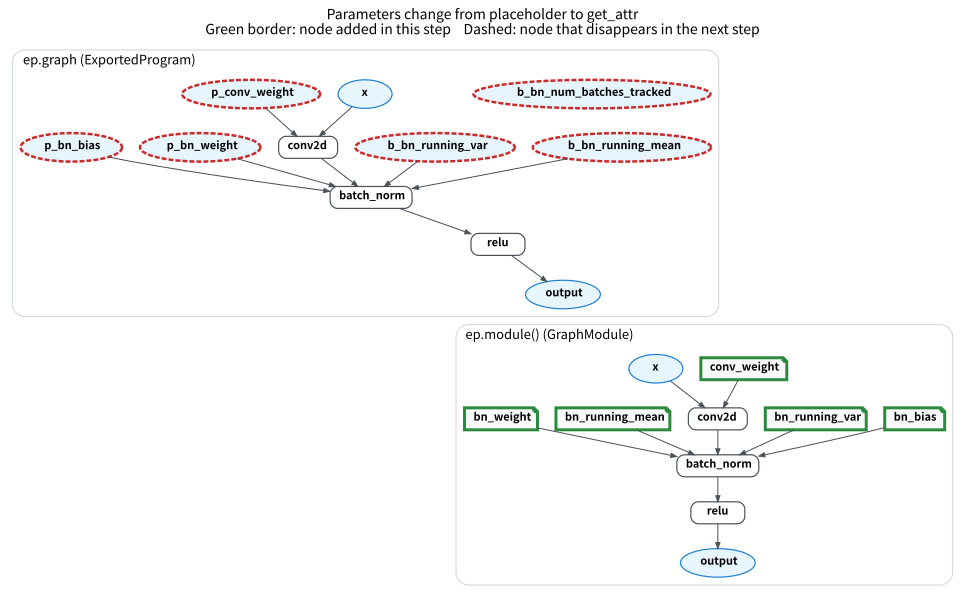

In [4]:
gm = ep.module()
draw_stages([(ep.graph_module, "ep.graph (ExportedProgram)"), (gm, "ep.module() (GraphModule)")],
            show_params=True, per_row=1, title="Parameters change from placeholder to get_attr")

Look at three things:

- At the top, `p_conv_weight`, `b_bn_running_mean`, ... are placeholders (ovals, which disappear in the next step); at the bottom they become `get_attr` (folded-corner boxes, green border), which read attributes off the GraphModule itself.
- Modules such as `nn.Conv2d` and `nn.BatchNorm2d` are gone; only the three operations `conv2d`, `batch_norm`, and `relu` remain. The whole graph is **flat**: no module hierarchy, just a sequence of ops.
  So for PT2E to find "a conv followed by a relu" it can only match op patterns on the graph; it cannot rely on "swapping out a module".
- `b_bn_num_batches_tracked` is unused in eval mode (M00-2 shows who uses it in train mode).

Listing node by node. The `op` column is the kind of fx node:

In [5]:
table([row[:4] for row in node_rows(gm, show_args=False)], ["#", "op", "name", "target"])

#,op,name,target
0,get_attr,conv_weight,conv.weight
1,get_attr,bn_weight,bn.weight
2,get_attr,bn_bias,bn.bias
3,get_attr,bn_running_mean,bn.running_mean
4,get_attr,bn_running_var,bn.running_var
5,get_attr,bn_num_batches_tracked,bn.num_batches_tracked
6,placeholder,x,x
7,call_module,_guards_fn,_guards_fn
8,call_function,conv2d,conv2d
9,call_function,batch_norm,batch_norm


- `placeholder`: an input of the graph; `get_attr`: reads a parameter or buffer on the GraphModule; `call_function`: calls a function (here, all ATen ops); `output`: the output of the graph.
- The `call_module` `_guards_fn` is a check that `ep.module()` inserts by default: on each call it verifies that the input matches the assumptions made at export time (for example, the shape). It has nothing to do with quantization. The earlier figure does not draw it.

The target of a `get_attr` is exactly the target in `graph_signature`, and the output of `ep.module()` is also identical to the original model:

In [6]:
targets = {spec.target for spec in ep.graph_signature.input_specs if spec.target is not None}
assert {n.target for n in gm.graph.nodes if n.op == "get_attr"} == targets
with torch.no_grad():
    err = (model(*ex) - gm(*ex)).abs().max().item()
print(f"max error between model(x) and ep.module()(x) = {err}")
assert err == 0

max error between model(x) and ep.module()(x) = 0.0


### A3. The meta of Each Node

Each node has a `meta` dict that records information collected at export time. The most commonly used entry is `meta["val"]`:
export runs the model once with "fake tensors" (FakeTensor, which have only shape, dtype, and device, but no values) and records what this node would produce.

In [7]:
rows = []
for n in gm.graph.nodes:
    if n.op == "call_function":
        val = n.meta["val"]
        rows.append([n.name, type(val).__name__, str(list(val.shape)), ", ".join(sorted(n.meta))])
table(rows, ["node", "type of meta['val']", "shape", "meta keys"])

node,type of meta['val'],shape,meta keys
conv2d,FakeTensor,"[2, 8, 16, 16]","from_node, nn_module_stack, stack_trace, tensor_meta, torch_fn, val"
batch_norm,FakeTensor,"[2, 8, 16, 16]","from_node, nn_module_stack, stack_trace, tensor_meta, torch_fn, val"
relu,FakeTensor,"[2, 8, 16, 16]","from_node, nn_module_stack, stack_trace, tensor_meta, torch_fn, val"


Dimension 0 of the shape is 2 because the batch of the example input is 2; export hard-codes shapes by default (`common.pt2e.export_module()` makes the batch dynamic, and M01 onward uses it).

There is nothing quantization-related in meta yet. The quantizer's annotations will later be written into the same `meta`, under the key `quantization_annotation` (M01-2, M03).

**Question to think about**: which node does the weight of conv2d on this graph come from?

In [8]:
conv = next(n for n in gm.graph.nodes if n.name == "conv2d")
weight_node = conv.args[1]
print(f"conv2d.args[1] = {weight_node.name} (op={weight_node.op}, target={weight_node.target})")
assert weight_node.op == "get_attr"

conv2d.args[1] = conv_weight (op=get_attr, target=conv.weight)


Answer: from the `get_attr` node `conv_weight` (target `conv.weight`); it is argument 1 of `conv2d`.
Later, the annotation for quantizing the weight hangs on the `conv2d` node that uses it: "what spec applies to the weight input edge of conv2d"?

## B. What Is ATen?

### B1. How to Read `aten.conv2d.default`

The `target` of the `conv2d` node on the graph is `torch.ops.aten.conv2d.default`. It has three parts:

In [9]:
conv_op = torch.ops.aten.conv2d
print(f"torch.ops.aten.conv2d             {type(conv_op).__name__}: all overloads of an op")
print(f"torch.ops.aten.conv2d.overloads() {conv_op.overloads()}")
print(f"torch.ops.aten.conv2d.default     {type(conv_op.default).__name__}: one of the overloads")
print(f"  schema: {conv_op.default._schema}")
print(f"compare torch.ops.aten.add.Tensor")
print(f"  schema: {torch.ops.aten.add.Tensor._schema}")
assert conv.target is torch.ops.aten.conv2d.default

torch.ops.aten.conv2d             OpOverloadPacket: all overloads of an op
torch.ops.aten.conv2d.overloads() ['default', 'padding']
torch.ops.aten.conv2d.default     OpOverload: one of the overloads
  schema: aten::conv2d(Tensor input, Tensor weight, Tensor? bias=None, SymInt[2] stride=[1, 1], SymInt[2] padding=[0, 0], SymInt[2] dilation=[1, 1], SymInt groups=1) -> Tensor
compare torch.ops.aten.add.Tensor
  schema: aten::add.Tensor(Tensor self, Tensor other, *, Scalar alpha=1) -> Tensor


`aten` (namespace) `.conv2d` (op) `.default` (overload). The same op can have several versions depending on argument types;
for example `add` has `add.Tensor` (add two tensors), `add.Scalar` (add a number to a tensor), and so on.

**ATen** is PyTorch's core tensor library, and almost all other Python/C++ interfaces are built on top of it ([official C++ documentation](https://docs.pytorch.org/cppdocs/));
`torch.ops.aten.*` are its op names on the Python side.

### B2. Three Styles, the Same Sequence of Ops After Export

The same model (conv → relu → mean → linear) written in three Python styles:

In [10]:
class FunctionalStyle(nn.Module):
    """Written entirely with torch.nn.functional; the parameters are declared by hand."""

    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.randn(8, 3, 3, 3))
        self.fc_w = nn.Parameter(torch.randn(4, 8))

    def forward(self, x):
        return F.linear(F.relu(F.conv2d(x, self.w, padding=1)).mean((2, 3)), self.fc_w)


class Inner(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 8, 3, padding=1, bias=False)
        self.act = nn.ReLU()

    def forward(self, x):
        return self.act(self.conv(x))


class WrappedStyle(nn.Module):
    """A custom Module wrapping nn.Conv2d / nn.ReLU / nn.Linear, one extra layer of Python class."""

    def __init__(self):
        super().__init__()
        self.inner = Inner()
        self.fc = nn.Linear(8, 4, bias=False)

    def forward(self, x):
        return self.fc(self.inner(x).mean((2, 3)))


class SequentialStyle(nn.Module):
    """Written with nn.Sequential."""

    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.ReLU())
        self.fc = nn.Linear(8, 4, bias=False)

    def forward(self, x):
        return self.fc(self.body(x).mean((2, 3)))

Each style is captured in two ways, and we list the operation nodes on the graph:

- `torch.fx.symbolic_trace(model)`: fx's original way of capturing (FX graph mode quantization before PT2E used it).
- `torch.export.export(model, (x,)).module()`: the way PT2E uses.

In [11]:
def fx_ops(gm):
    """symbolic_trace graph: call_module prints the module class (and its path in the model), call_function prints the function name, call_method prints the method name."""
    out = []
    for n in gm.graph.nodes:
        if n.op == "call_module":
            out.append(f"module {type(gm.get_submodule(n.target)).__name__}({n.target})")
        elif n.op == "call_function":
            out.append(f"function {n.target.__name__}")
        elif n.op == "call_method":
            out.append(f"method {n.target}")
    return out


def export_ops(gm):
    return [n.target for n in gm.graph.nodes if n.op == "call_function"]


ex_small = (torch.randn(2, 3, 8, 8),)
styles = [FunctionalStyle, WrappedStyle, SequentialStyle]
fx_lists = [fx_ops(torch.fx.symbolic_trace(cls())) for cls in styles]
export_lists = [export_ops(export(cls().eval(), ex_small).module()) for cls in styles]
table([[cls.__name__, " → ".join(f), " → ".join(short(t) for t in e)]
       for cls, f, e in zip(styles, fx_lists, export_lists)],
      ["Style", "symbolic_trace nodes", "export nodes (aten.*)"])

Style,symbolic_trace nodes,export nodes (aten.*)
FunctionalStyle,function conv2d → function relu → method mean → function linear,conv2d → relu → mean → linear
WrappedStyle,module Conv2d(inner.conv) → module ReLU(inner.act) → method mean → module Linear(fc),conv2d → relu → mean → linear
SequentialStyle,module Conv2d(body.0) → module ReLU(body.1) → method mean → module Linear(fc),conv2d → relu → mean → linear


In [12]:
assert all(e == export_lists[0] for e in export_lists)  # export: the node.target is identical for all three styles
assert len({tuple(f) for f in fx_lists}) == 3  # symbolic_trace: all three styles differ
print("export node.target:", [str(t) for t in export_lists[0]])

export node.target: ['aten.conv2d.default', 'aten.relu.default', 'aten.mean.dim', 'aten.linear.default']


- The **symbolic_trace** graph follows the way the model is written: `nn.Conv2d` stays a `call_module` (at the module level; even its paths in the model, `inner.conv` and `body.0`, are kept),
  `F.conv2d` is a Python function, and `.mean()` is a method.
  The same conv comes in several shapes, and whoever receives this graph has to recognize every Module class and every Python style.
- The **export** graph is the same sequence of `aten.*` ops no matter how the model is written; the module hierarchy is also flattened.

This matters for backends: given a graph, a backend has to decide node by node, "do I have a kernel for this operation?" With the graph's vocabulary unified to ATen ops, the backend only has to compare against its own list of supported ops.
The PyTorch documentation positions the Core ATen op set the same way: it is "designed to serve as the functional IR to interface with backends"
([IRs](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/torch.compiler_ir.html)).
The PT2E quantizer finds convs with `node.target == torch.ops.aten.conv2d.default`, which also relies on this (M03).
The chapter overview explains this in more detail.

### B3. The Layers, Top to Bottom

| Layer | What it is | In the exported graph |
|---|---|---|
| `nn.Conv2d`, custom Module | Python class | gone after export |
| `F.conv2d` | Python function | gone after export |
| `torch.ops.aten.conv2d.default` | the name of an op | this is the `node.target` |
| C++ implementations on each device (kernels) | the code that does the actual computation | not on the graph; chosen at run time (B4) |

An ATen op can also be decomposed into lower-level ops (for example `conv2d` → `convolution`); see M00-3.

### B4. How an Op Finds Its Kernel at Run Time

Export leaves only the op's **name** on the graph. At run time (eager mode, taking `z = x + y` with x and y both CPU tensors as the example):

1. Python's `x + y` calls `torch.add`, which enters ATen's `aten::add.Tensor`.
2. The **dispatcher** looks at the tensors' dispatch keys and decides which layer of implementation to use: backend (CPU/CUDA/MPS...), autograd, quantized, and so on. When gradients are needed, the call first passes through the autograd layer.
3. The backend's kernel runs: ATen itself ships CPU, CUDA, and MPS implementations; some ops further call libraries such as cuBLAS and cuDNN.
4. The dtype (float32, etc.) is usually switched inside the kernel, not decided at the dispatcher layer.
5. The result is wrapped as a Tensor and returned to Python.

After dispatch, a kernel may still pick an implementation based on the inputs (M07-1 uses the profiler to see conv switching implementations by batch size).
The above is a general description; the order of the steps was not traced line by line through the source code.

## Summary

- `torch.export.export()` returns an ExportedProgram: parameters are placeholders and `graph_signature` records the correspondence; `ep.module()` binds the parameters back as `get_attr`, and PT2E uses this GraphModule.
- The graph is flat and contains only ATen ops; each node's `meta["val"]` records the output's shape/dtype, and quantization annotations are later written in `meta` too.
- Different Python styles export to the same sequence of ATen ops, so backends and quantizers only need to recognize this set of ops.